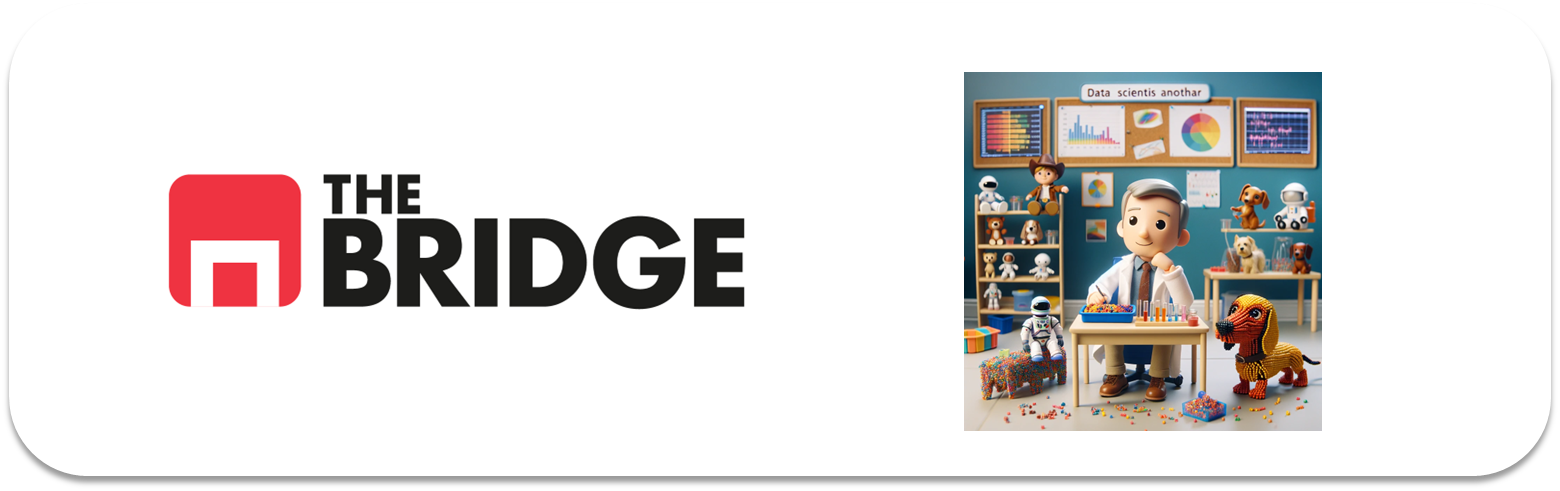

## PRACTICA OBLIGATORIA: ANÁLISIS UNIVARIANTE

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook. Te dejo una que vas a necesitar sí o sí

In [7]:

import seaborn as sns
import pandas as pd
import numpy as np




### #1 Preparación


### #1.1


Carga en un dataframe los datos del titanic a partir de un dataset de seaborn. Para ello:

* ejecuta ```python sns.get_dataset_names()```
* localiza el nombre que puede ser el adecuado para el ejercicio
* Asigna la salida de ```sns.load_dataset(<nombre_del_dataset>)``` a una variable "df_titanic"

In [8]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [9]:
df_titanic = sns.load_dataset('titanic')

### #1.2

Muestra una porción del dataset ("df_titanic") y su info general. ¿Hay nulos?

In [10]:
df_titanic.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [11]:
df_titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


### #1.3

Obtén el porcentaje de nulos y decide que hacer con las columnas con nulos y ejecútalo. Además deshazte de la columna "parch" que no la emplearemos.

In [12]:
porcentaje_nulos = (df_titanic.isnull().sum() / len(df_titanic)) * 100
porcentaje_nulos

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

In [13]:
df_titanic2 = df_titanic.copy()
del df_titanic2['parch']
del df_titanic2['deck']
df_titanic2
# el porcentaje de valores nulls que hay en deck es demasiado alto, y además son strings, por lo que no se va a poder analizar nada con esos datos. 
# 'Deck' es la cubierta donde estaba su camarote, pero podemos saber un valor parecido en funcion de la clase y el precio que habia 

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,S,Second,man,True,Southampton,no,True
887,1,1,female,19.0,0,30.0000,S,First,woman,False,Southampton,yes,True
888,0,3,female,NaN,1,23.4500,S,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,30.0000,C,First,man,True,Cherbourg,yes,True


In [14]:
df_titanic2.groupby('sex')['who'].value_counts()

sex     who  
female  woman    271
        child     43
male    man      537
        child     40
Name: count, dtype: int64

In [15]:
filtro = df_titanic2['who'] == 'woman'
mediana_mujer = df_titanic2.loc[filtro, 'age'].median()
mediana_mujer

np.float64(30.0)

In [16]:
filtro2 = df_titanic2['who'] == 'man'
mediana_hombre = df_titanic2.loc[filtro2, 'age'].median()

In [17]:
filtro3 = (df_titanic2['sex'] == 'female') & (df_titanic2['who'] == 'child')
mediana_nina = df_titanic2.loc[filtro3, 'age'].median()

In [18]:
filtro4 = (df_titanic2['sex'] == 'male') & (df_titanic2['who'] == 'child')
mediana_nino = df_titanic2.loc[filtro4, 'age'].median()

In [19]:
mascara = df_titanic2['age'].isna()

In [20]:
df_titanic2.loc[filtro & mascara, 'age'] = mediana_mujer

In [21]:
df_titanic2.loc[filtro2 & mascara, 'age'] = mediana_hombre

In [22]:
df_titanic2.loc[filtro3 & mascara, 'age'] = mediana_nina

In [23]:
df_titanic2.loc[filtro4 & mascara, 'age'] = mediana_nino

In [24]:
moda_embarked = df_titanic2['embarked'].mode(dropna=True)
moda_embarked

0    S
Name: embarked, dtype: str

In [25]:
modal = df_titanic2['embarked'].isna()

In [26]:
df_titanic2.loc[modal,'embarked'] = 'Southampton'

In [27]:
moda_town = df_titanic2['embark_town'].mode(dropna=True)
moda_town

0    Southampton
Name: embark_town, dtype: str

In [28]:
df_titanic2.loc[modal, 'embark_town'] = 'Southampton'

In [29]:
df_titanic2

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,S,Second,man,True,Southampton,no,True
887,1,1,female,19.0,0,30.0000,S,First,woman,False,Southampton,yes,True
888,0,3,female,30.0,1,23.4500,S,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,30.0000,C,First,man,True,Cherbourg,yes,True


In [30]:
# se ha calculado la mediana por grupos de edad entre adultos hombres, adultos mujeros, niñas y niños. 
# De esta manera se podrá rellenar de manera más exacta los valores perdidos de la edad utilizando esos valores

### #1.4
Sobre el dataset "limpio". Rellena la tabla de descripción (muy breve) de lo que es cada columna en función de su nombre y los valores. Para ayudarte:
* Se trata del dataset que reune lo más parecido a un manifiesto de supervivientes y fallecidos en el viaje.
* sibsp: Es el numero de familiares que viajan con la persona indicada en el manifiesto (lista de pasajeros)
* embarked: Es la incial de la letra de la ciudad donde embarcó la persona.




| Columna/Variable | Descripción |
| ---------------- | ----------- |
| -       | - |




| Columna   | Descripción   |
|---    |---    |
| Survived  | Si sobrevivieron o no |
| Pclass    | La clase de billete que compraron |
| Sex   | El género del pasajero    |
| Age   | Edad que tenían los pasajeros |
| Sibsp | El número de familiares que viajaban con la persona indicada en la lista de pasajeros |
| Fare  | El precio del billete |
| Embarked  | En qué puerto embarcaron  |
| Class | La clase de billete que compraron |
| Who   | Si eran hombre, mujer o niño el pasajero  |
| Adult_male    | Si era un hombre adulto o no el pasajero  |
| Embark_town   | Ciudad en la que embarcó el pasajero  |
| Alive | Si sobrevivió o no    |
| Alone | Si viajaba solo o no  |


### #1.5

Busca en internet las tres ciudades que visitó el Titanic antes de poner rumbo a su destino y llegar a alta mar. Cambia las iniciales por esos valores.

In [31]:
# Partió de Southampton (Inglaterra), hizo escala en Cherburgo (Francia) y Queenstown (Irlanda), después puso rumbo a Nueva York

df_titanic2.embarked = df_titanic2.embarked.replace({'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'})
df_titanic2

,survived,pclass,sex,age,sibsp,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,7.2500,Southampton,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,71.2833,Cherbourg,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,7.9250,Southampton,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,53.1000,Southampton,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,8.0500,Southampton,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,13.0000,Southampton,Second,man,True,Southampton,no,True
887,1,1,female,19.0,0,30.0000,Southampton,First,woman,False,Southampton,yes,True
888,0,3,female,30.0,1,23.4500,Southampton,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,30.0000,Cherbourg,First,man,True,Cherbourg,yes,True


In [32]:
df_titanic2.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          891 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   fare         891 non-null    float64 
 6   embarked     891 non-null    str     
 7   class        891 non-null    category
 8   who          891 non-null    str     
 9   adult_male   891 non-null    bool    
 10  embark_town  891 non-null    str     
 11  alive        891 non-null    str     
 12  alone        891 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(3), str(5)
memory usage: 100.3 KB


### #2 Análisis

Sabiendo que el objetivo de nuestro análisis es hacer un estudio de la superviviencia y mortalidad en el viaje... Haz un análisis univariante completo y ordenado de las siguientes variables:
["survived","who","age","fare","class","embarked","alone"]
Nota: Si quieres añadir más, perfecto.

Separa el análisis en categóricas (incluyendo binarias) y numéricas. Muestra valores, gráficas y conclusiones/observaciones (2 o 3 por variable)

| Variable  | Tipo  |
| ---   | ---   |
| Survived  | Categórica binaria    |
| Who   | Categórica    |
| Age   | Numérica Continua |
| Fare  | Numérica Continua |
| Class | Categórica    |
| Embarked  | Categórica    |
| Alone | Categórica binaria    |

In [33]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import bootcampviztools

### #2.1 Categóricas

In [49]:
# Análisis variable survived - categórica binaria

# Frecuencia absoluta
frec_abs_s = df_titanic2['survived'].value_counts()

# Frecuencia relativa

frec_rel_s = df_titanic2['survived'].value_counts(normalize=True) * 100

# Tabla con Frecuencias Absolutas y Relativas

frec_df_s = pd.DataFrame({'Frecuencia Absoluta': frec_abs_s, 'Frecuencia Relativa': frec_rel_s})
print(frec_df_s)

# Estadísticas básicas
df_titanic2['survived'].describe()


          Frecuencia Absoluta  Frecuencia Relativa
survived                                          
0                         549            61.616162
1                         342            38.383838


count    891.000000
mean       0.383838
std        0.486592
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: survived, dtype: float64

Sobrevivieron 342 personas, que representan el 38,38% y murieron 549 personas, que representan el 61,61%.
La media (mean) es del 0,38 y la desviación típica (std) es 0,48, que es un valor muy alto. Por lo que nos dice, que los datos están muy alejados de la media.

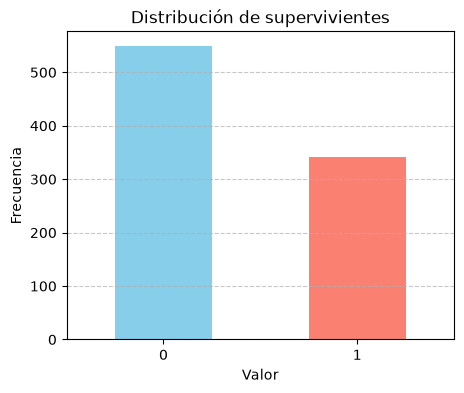

In [50]:
plt.figure(figsize=(5, 4))
frec_abs_s.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Distribución de supervivientes')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [51]:
# Análisis variable who

# Frecuencia absoluta
frec_abs_w = df_titanic2['who'].value_counts()

# Frecuencia relativa

frec_rel_w = df_titanic2['who'].value_counts(normalize=True) * 100

# Tabla con Frecuencias Absolutas y Relativas

frec_df_w = pd.DataFrame({'Frecuencia Absoluta': frec_abs_w, 'Frecuencia Relativa': frec_rel_w})
print(frec_df_w)

# Estadísticas básicas
df_titanic2['who'].describe()



       Frecuencia Absoluta  Frecuencia Relativa
who                                            
man                    537            60.269360
woman                  271            30.415264
child                   83             9.315376


count     891
unique      3
top       man
freq      537
Name: who, dtype: object

Nos dice que había más hombres, que mujeres y niños. El 60,26% eran los hombres, frente al 30,42% que eran mujeres y solo un 9,32% eran los niños.

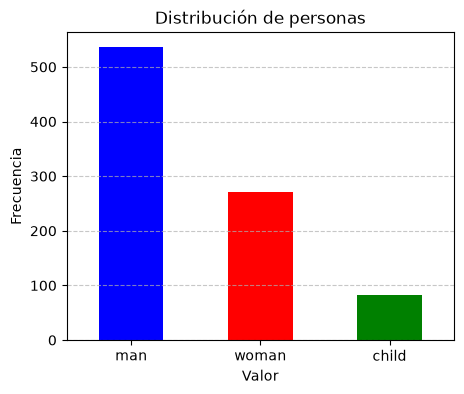

In [53]:
plt.figure(figsize=(5, 4))
frec_abs_w.plot(kind='bar', color=['blue', 'red', 'green'])
plt.title('Distribución de personas')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [56]:
# Análisis variable class

# Frecuencia absoluta
frec_abs_c = df_titanic2['class'].value_counts()

# Frecuencia relativa

frec_rel_c = df_titanic2['class'].value_counts(normalize=True) * 100

# Tabla con Frecuencias Absolutas y Relativas

frec_df_c = pd.DataFrame({'Frecuencia Absoluta': frec_abs_c, 'Frecuencia Relativa': frec_rel_c})
print(frec_df_c)

# Estadísticas básicas
df_titanic2['class'].describe()

        Frecuencia Absoluta  Frecuencia Relativa
class                                           
Third                   491            55.106622
First                   216            24.242424
Second                  184            20.650954


count       891
unique        3
top       Third
freq        491
Name: class, dtype: object

De las tres clases que había, más de la mitad de las personas compraron tercera clase (55,11%), frente al 24,24% que compraron primera clase y el 20,65% que compraron segunda clase.

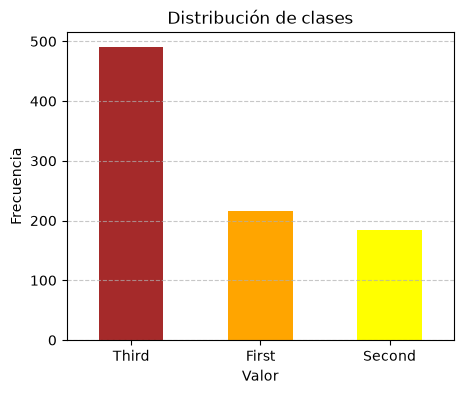

In [57]:
plt.figure(figsize=(5, 4))
frec_abs_c.plot(kind='bar', color=['brown', 'orange', 'yellow'])
plt.title('Distribución de clases')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [58]:
# Análisis embarked

# Frecuencia absoluta
frec_abs_e = df_titanic2['embarked'].value_counts()

# Frecuencia relativa

frec_rel_e = df_titanic2['embarked'].value_counts(normalize=True) * 100

# Tabla con Frecuencias Absolutas y Relativas

frec_df_e = pd.DataFrame({'Frecuencia Absoluta': frec_abs_e, 'Frecuencia Relativa': frec_rel_e})
print(frec_df_e)

# Estadísticas básicas
df_titanic2['embarked'].describe()


             Frecuencia Absoluta  Frecuencia Relativa
embarked                                             
Southampton                  646            72.502806
Cherbourg                    168            18.855219
Queenstown                    77             8.641975


count             891
unique              3
top       Southampton
freq              646
Name: embarked, dtype: object

Se puede concluir que la mayoría de las personas embarcaron principalmente en Southampton (77,5%), mientras que en Cherbourg solo embarcó el 18,86% y en Queenstown únicamente el 8,64%.

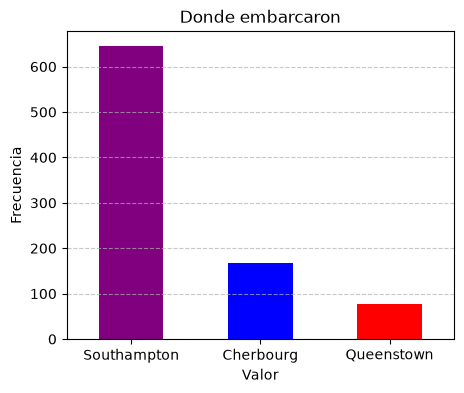

In [60]:
plt.figure(figsize=(5, 4))
frec_abs_e.plot(kind='bar', color=['purple', 'blue', 'red'])
plt.title('Donde embarcaron')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [61]:
# Análisis de la variable alone

# Frecuencia absoluta
frec_abs_a = df_titanic2['alone'].value_counts()

# Frecuencia relativa

frec_rel_a = df_titanic2['alone'].value_counts(normalize=True) * 100

# Tabla con Frecuencias Absolutas y Relativas

frec_df_a = pd.DataFrame({'Frecuencia Absoluta': frec_abs_a, 'Frecuencia Relativa': frec_rel_a})
print(frec_df_a)

# Estadísticas básicas
df_titanic2['alone'].describe()


       Frecuencia Absoluta  Frecuencia Relativa
alone                                          
True                   537             60.26936
False                  354             39.73064


count      891
unique       2
top       True
freq       537
Name: alone, dtype: object

Más de la mitad de las personas viajaban solas (60,27%) frente al 39,73% que iban acompañados.

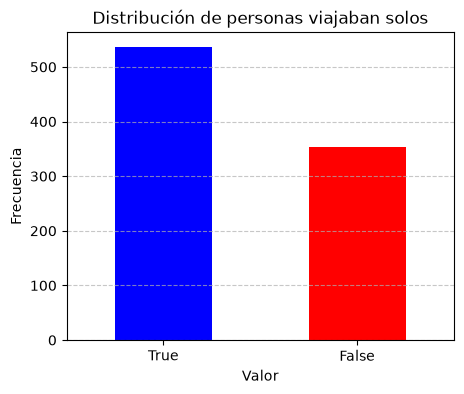

In [65]:
plt.figure(figsize=(5, 4))
frec_abs_a.plot(kind='bar', color=['blue', 'red'])
plt.title('Distribución de personas viajaban solos')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### #2.2 Numéricas

In [ ]:
# estudio por frecuencias absolutas
def frecuencias(df, columna_categorica, porcentaje = True):
    frec_abs = df[columna_categorica].value_counts() # Values_counts() me da las frecuencias absolutas
    frec_rel = df[columna_categorica].value_counts(normalize=True) * (100 if porcentaje else 1)  # Si activo el argumento normalize me da las relativas en tanto por 1, el argumento porcentaje de la función me permite pasarlo a tanto por cien

    # Crear DataFrame con ambas frecuencias
    frec_df = pd.DataFrame({'Frecuencia Absoluta': frec_abs, 'Frecuencia Relativa': frec_rel})

    return frec_df
'''
df_frecuencias = frecuencias(df_admisiones, "Major")
df_frecuencias
'''

'\ndf_frecuencias = frecuencias(df_admisiones, "Major")\ndf_frecuencias\n'

In [71]:
# Análisis de Age

# Tendencia central
media_a = df_titanic2['age'].mean().round(2)
mediana_a = df_titanic2['age'].median()
moda_a = df_titanic2['age'].mode()

# Medidas de dispersion
min_a = df_titanic2['age'].min()
max_a = df_titanic2 ['age'].max()
rango_a = max_a - min_a
var_a = df_titanic2['age'].var()
desv_a = df_titanic2['age'].std()
coef_a = desv_a / media_a

analisis_age = pd.DataFrame({'Media':media_a, 'Mediana':mediana_a, 'Moda':moda_a, 'Mínimo':min_a, 'Máximo':max_a, 'Rango':rango_a, 'Varianza': var_a, 'Desviación Típica': desv_a, 'Coeficiente Variacion':coef_a})
analisis_age

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desviación Típica,Coeficiente Variacion
0,29.76,30.0,30.0,0.42,80.0,79.58,169.066828,13.00257,0.436914


In [72]:
df_titanic2['age'].describe()

count    891.000000
mean      29.758889
std       13.002570
min        0.420000
25%       22.000000
50%       30.000000
75%       35.000000
max       80.000000
Name: age, dtype: float64

Al ser la media y la mediana prácticamente iguales, nos dice que no hay asimetría respecto a la edad y que la edad media de los pasajeros era de 30 años. La persona más mayor tenía 80 años y la más pequeña no tenía ni 6 meses (0,42 años). Una variable tan alta, me indica que mis datos están muy dispersos respecto a la edad, y que tienen una variación de 13 puntos respecto a la media de edad, que es 30. El coeficiente de variabilidad cercano al 0.44 indica una variabilidad moderada-alta.

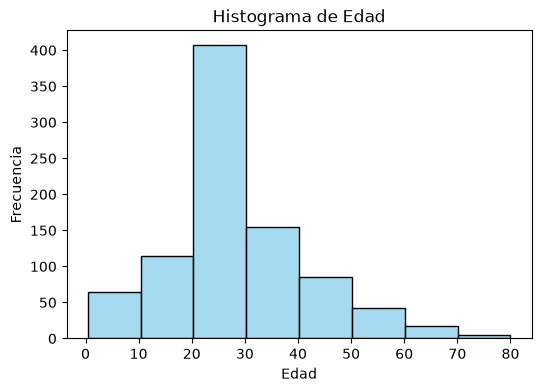

In [73]:
plt.figure(figsize=(6,4))
sns.histplot(df_titanic2['age'], bins=8, kde=False, color='skyblue')
plt.title('Histograma de Edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

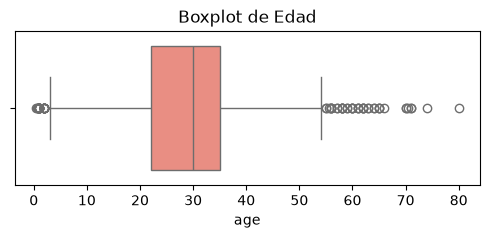

In [74]:
plt.figure(figsize=(6,2))
sns.boxplot(x=df_titanic2['age'], color='salmon')
plt.title('Boxplot de Edad')
plt.show()

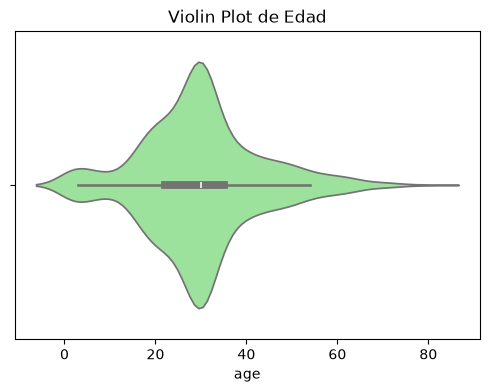

In [75]:
plt.figure(figsize=(6,4))
sns.violinplot(x=df_titanic2['age'], color='lightgreen')
plt.title('Violin Plot de Edad')
plt.show()

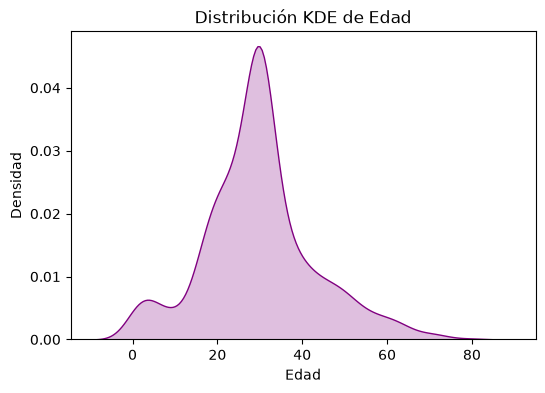

In [76]:
plt.figure(figsize=(6,4))
sns.kdeplot(df_titanic2['age'], fill=True, color='purple')
plt.title('Distribución KDE de Edad')
plt.xlabel('Edad')
plt.ylabel('Densidad')
plt.show()

In [77]:
# Análisis de fare
df_titanic2['fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64

In [78]:
# Tendencia central
media_f = df_titanic2['fare'].mean().round(2)
mediana_f = df_titanic2['fare'].median()
moda_f = df_titanic2['fare'].mode()

# Medidas de dispersion
min_f = df_titanic2['fare'].min()
max_f = df_titanic2 ['fare'].max()
rango_f = max_f - min_f
var_f = df_titanic2['fare'].var()
desv_f = df_titanic2['fare'].std()
coef_f = desv_f/ media_f

analisis_fare = pd.DataFrame({'Media':media_f, 'Mediana':mediana_f, 'Moda':moda_f, 'Mínimo':min_f, 'Máximo':max_f, 'Rango':rango_f, 'Varianza': var_f, 'Desviación Típica': desv_f, 'Coeficiente Variacion':coef_f})
analisis_fare

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desviación Típica,Coeficiente Variacion
0,32.2,14.4542,8.05,0.0,512.3292,512.3292,2469.436846,49.693429,1.543274


Lo primero que podemos ver es que el precio máximo del billete era de $512,33 y que el mínimo era de $0. Esto se explica porque la tripulación no pagaba billete. La media y la mediana están muy alejadas, es casi el doble la media, por lo que podemos decir que tendrá una distribución asimétrica de los billetes. Esto también se refleja en que el valore de la varianza es enorme y que la desviación típica es casi del 50%. 

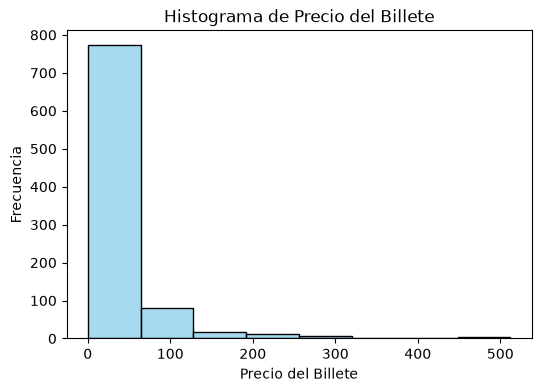

In [79]:
plt.figure(figsize=(6,4))
sns.histplot(df_titanic2['fare'], bins=8, kde=False, color='skyblue')
plt.title('Histograma de Precio del Billete')
plt.xlabel('Precio del Billete')
plt.ylabel('Frecuencia')
plt.show()

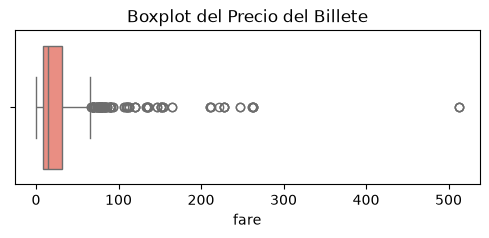

In [80]:
plt.figure(figsize=(6,2))
sns.boxplot(x=df_titanic2['fare'], color='salmon')
plt.title('Boxplot del Precio del Billete')
plt.show()

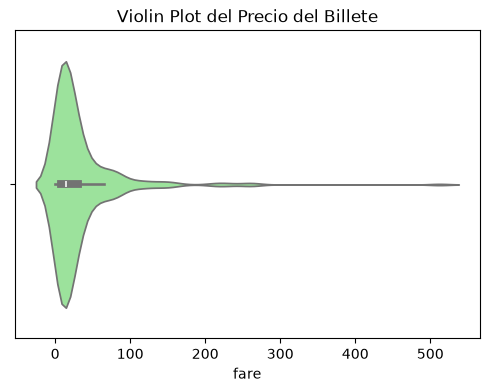

In [81]:
plt.figure(figsize=(6,4))
sns.violinplot(x=df_titanic2['fare'], color='lightgreen')
plt.title('Violin Plot del Precio del Billete')
plt.show()

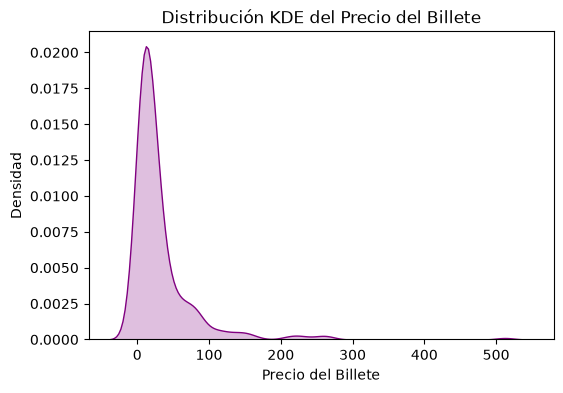

In [82]:
plt.figure(figsize=(6,4))
sns.kdeplot(df_titanic2['fare'], fill=True, color='purple')
plt.title('Distribución KDE del Precio del Billete')
plt.xlabel('Precio del Billete')
plt.ylabel('Densidad')
plt.show()